In [ ]:
import polars as pl
import matplotlib.pyplot as plt

['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


/tmp/ipykernel_6006/3669371845.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()
/tmp/ipykernel_6006/3669371845.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend()


Text(0.05, 1.02, 'c')

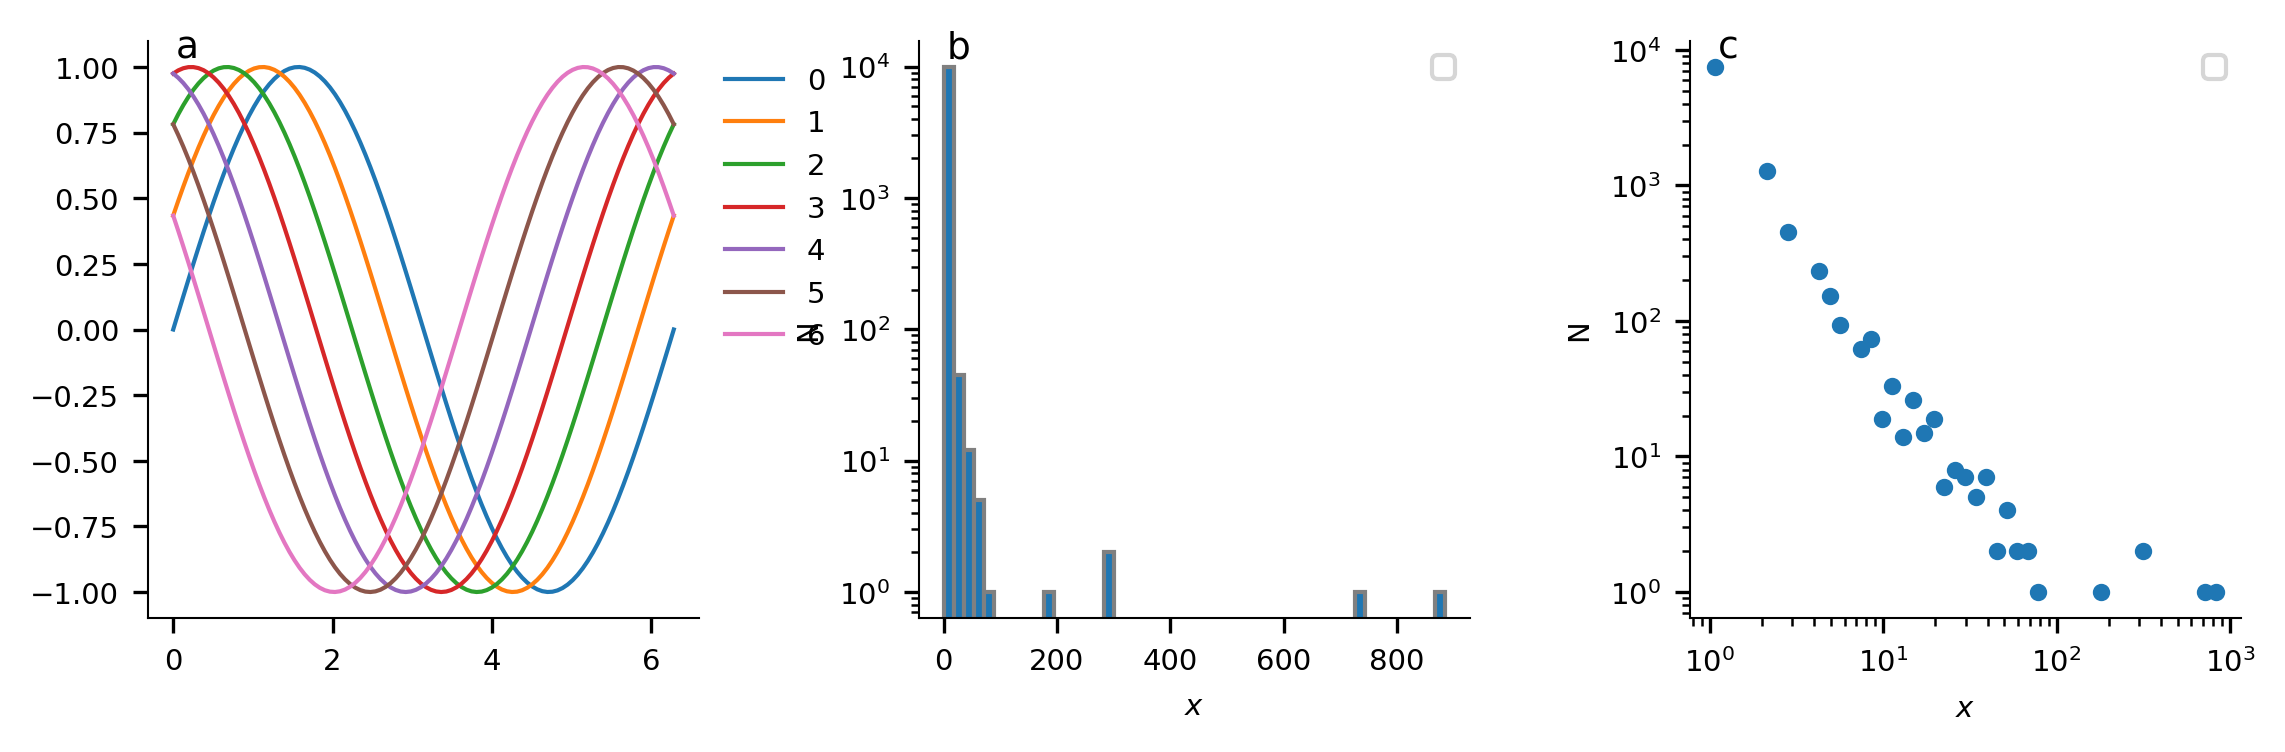

In [14]:
# check format, color and styles

from matplotlib import pyplot as plt
import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
# https://github.com/garrettj403/SciencePlots
print(plt.rcParams['axes.prop_cycle'].by_key()['color'])


fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(9,2.5))
fig.subplots_adjust(hspace=0.1, wspace=0.4)

n = 7
x = np.linspace(0, 2*np.pi, 100)
for i in range(n):
    ax1.plot(x, np.sin(x+np.pi/n*i), label=i)
ax1.spines[['right', 'top']].set_visible(False)
ax1.tick_params(which='both', top=False, right=False)
ax1.legend(loc='upper left', bbox_to_anchor=(1,1),frameon=False)
ax1.text(0.05, 1.02, 'a', va='top', transform=ax1.transAxes, fontsize=9)


np.random.seed(0)
a = 2.5  # べき分布の指数（べき指数）
size = 10000  # データのサイズ
data = np.random.zipf(a, size)

ax2.hist(data, bins=50, log=True, edgecolor='gray')
ax2.set_xlabel('$x$')
ax2.set_ylabel('N')
ax2.spines[['right', 'top']].set_visible(False)
ax2.tick_params(which='both', top=False, right=False)
ax2.legend()
ax2.text(0.05, 1.02, 'b', va='top', transform=ax2.transAxes, fontsize=9)

bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)
hist, bin_edges = np.histogram(data, bins=bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax3.scatter(bin_centers, hist, s=10)
ax3.set_xscale('log')  # x軸を対数スケールに設定
ax3.set_yscale('log')  # y軸を対数スケールに設定
ax3.set_xlabel('$x$')
ax3.set_ylabel('N')
ax3.spines[['right', 'top']].set_visible(False)
ax3.tick_params(which='both', top=False, right=False)
ax3.legend()
ax3.text(0.05, 1.02, 'c', va='top', transform=ax3.transAxes, fontsize=9)

In [2]:
CNS_papers_details_df =  pl.read_parquet("./data/CNS_papers_inferred_subjects_Life.parquet")
CNS_citing_preprints_df = pl.read_parquet("./data/citing_preprints_full_enhanced.parquet").filter(pl.col("work_id").is_in(CNS_papers_details_df["work_id"].to_list()))
journal_detail = pl.read_parquet("./data/CNS_journal_inception.parquet")
preprint = pl.read_parquet("./data/preprints_opal_0129_curation_imputed.parquet").drop_nulls("work_id")

In [3]:
preprint.group_by(pl.col("curated_doi").is_not_null()).len()

curated_doi,len
bool,u32
false,1167721
true,1848524


In [4]:
print(CNS_citing_preprints_df.unique("server").get_column("server").to_list())
CNS_citing_preprints_df.unique("primary_category").get_column("primary_category").to_list()


['psyarxiv', 'medrxiv', 'socarxiv', 'arxiv', 'osf', 'biorxiv']


['cond-mat.mes-hall',
 'infectious diseases',
 'cs.DS',
 'pediatrics',
 '',
 'physics.class-ph',
 'cs.CR',
 'cs.CE',
 'Neuroscience',
 'cs.MA',
 'genetics',
 'cs.NI',
 'scientific communication and education',
 'cond-mat.stat-mech',
 'math.ST',
 'cs.AI',
 'dentistry and oral medicine',
 'q-bio.BM',
 'q-bio.GN',
 'stat.ML',
 'neurology',
 'bioengineering',
 'eess.IV',
 'otolaryngology',
 'gastroenterology',
 'Arts and Humanities',
 'rehabilitation medicine and physical therapy',
 'primary care research',
 'surgery',
 'Molecular Biology',
 'econ.TH',
 'adap-org',
 'cs.CY',
 'q-bio.NC',
 'math.HO',
 'math.RT',
 'clinical trials',
 'Law',
 'Synthetic Biology',
 'math.PR',
 'math.CO',
 'health economics',
 'astro-ph.CO',
 'hiv aids',
 'stat.OT',
 'sexual and reproductive health',
 'Cancer Biology',
 'geriatric medicine',
 'q-bio.SC',
 'Genomics',
 'ecology',
 'cond-mat.other',
 'cs.MS',
 'nlin.CD',
 'evolutionary biology',
 'cond-mat.str-el',
 'Epidemiology',
 'cs.SE',
 'Immunology',
 'phys

In [5]:
CNS_paper_yearly_count = (
    CNS_papers_details_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.count().alias("total_article"),
        pl.col("ref_count").sum().alias("total_ref_count")
    )
    .sort("publication_year")
)

CNS_paper_yearly_count.filter(pl.col("publication_year") >= 2000).sort("publication_year")

/tmp/ipykernel_6006/1689210000.py:7: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("total_article"),


publication_year,total_article,total_ref_count
i64,u32,u32
2000,2503,67729
2001,2569,71251
2002,2600,75931
2003,2632,76473
2004,3692,125044
…,…,…
2019,3890,211019
2020,4164,234788
2021,3776,223413


In [6]:
CNS_citing_preprints_df

work_id,referenced_works,doi,primary_category,server,curated_doi,published_date,publication_year_preprint,primary_location_id,publication_year
str,str,str,str,str,str,datetime[μs],i32,str,i64
"""W4389729874""","""W4310253617""","""10.1101/2022.11.22.22282629""","""epidemiology""","""medrxiv""",null,2022-11-27 00:00:00,2022,"""S110447773""",2023
"""W3215743644""","""W2101234009""","""10.48550/arxiv.1201.0490""","""cs.LG""","""arxiv""",null,2012-01-02 00:00:00,2012,"""S169236886""",2021
"""W3215743644""","""W4300122070""","""10.48550/arxiv.1803.11136""","""stat.ML""","""arxiv""",null,2018-03-29 00:00:00,2018,"""S169236886""",2021
"""W3215743644""","""W2580527863""","""10.48550/arxiv.1701.06772""","""cs.CV""","""arxiv""",null,2017-01-24 00:00:00,2017,"""S169236886""",2021
"""W3215743644""","""W2775795276""","""10.48550/arxiv.1712.04621""","""cs.CV""","""arxiv""",null,2017-12-13 00:00:00,2017,"""S169236886""",2021
…,…,…,…,…,…,…,…,…,…
"""W2770120368""","""W1567766502""","""10.48550/arxiv.astro-ph/961104…","""astro-ph""","""arxiv""",null,1996-11-06 00:00:00,1996,"""S137773608""",1998
"""W2770120368""","""W1819454925""","""10.48550/arxiv.astro-ph/971125…","""astro-ph""","""arxiv""",null,1997-11-21 00:00:00,1997,"""S137773608""",1998
"""W2770120368""","""W3080337754""","""10.48550/arxiv.astro-ph/970116…","""astro-ph""","""arxiv""",null,1997-01-22 00:00:00,1997,"""S137773608""",1998


In [7]:
noncurated = pl.when(pl.col("curated_doi").is_null()).then(pl.col("work_id"))
curated = pl.when(pl.col("curated_doi").is_not_null()).then(pl.col("work_id"))

pub_year_preprint_citation_count = (
    CNS_citing_preprints_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.n_unique("work_id").alias("num_citing_preprints"),
        pl.count("work_id").alias("num_citation_preprints"),
        noncurated.n_unique().alias("num_citing_noncurated_preprints"),
        noncurated.count().alias("num_citation_noncurated_preprints"),
        curated.n_unique().alias("num_citing_curated_preprints"),
        curated.count().alias("num_citation_curated_preprints"),
    )
    .sort("publication_year")
)

pub_year_preprint_citation_count

publication_year,num_citing_preprints,num_citation_preprints,num_citing_noncurated_preprints,num_citation_noncurated_preprints,num_citing_curated_preprints,num_citation_curated_preprints
i64,u32,u32,u32,u32,u32,u32
1983,1,1,1,1,1,0
1998,2,6,2,6,1,0
1999,2,3,2,1,3,2
2003,1,1,1,1,1,0
2004,2,2,1,0,2,2
…,…,…,…,…,…,…
2019,519,893,321,465,323,428
2020,970,2252,618,1025,636,1227
2021,1068,2742,718,1311,689,1431


In [8]:
pub_year_preprint_citation_count.filter(
    pl.col("publication_year") == 2016
).select(['num_citation_curated_preprints', 'num_citation_noncurated_preprints'])

num_citation_curated_preprints,num_citation_noncurated_preprints
u32,u32
75,68


In [9]:
citing_preprint_probability = (
    pub_year_preprint_citation_count
    # .join(preprint_count, on="publication_year", how="left")
    .join(CNS_paper_yearly_count, on="publication_year", how="inner")
    .filter(pl.col("publication_year").is_between(2000,2024))
    .with_columns(
        (pl.col("num_citing_preprints") / pl.col("total_article")).alias("citing_preprint_probability"),
        (pl.col("num_citing_noncurated_preprints") / pl.col("total_article")).alias("citing_noncurated_preprint_probability"),
        (pl.col("num_citing_curated_preprints") / pl.col("total_article")).alias("citing_curated_preprint_probability"),
        (pl.col("num_citation_preprints") / pl.col("total_ref_count")).alias("citation_preprint_probability"),
        (pl.col("num_citation_noncurated_preprints") / pl.col("total_ref_count")).alias("citation_noncurated_preprint_probability"),
        (pl.col("num_citation_curated_preprints") / pl.col("total_ref_count")).alias("citation_curated_preprint_probability")
    )
    .sort("publication_year")
)

In [10]:
citing_preprint_probability

publication_year,num_citing_preprints,num_citation_preprints,num_citing_noncurated_preprints,num_citation_noncurated_preprints,num_citing_curated_preprints,num_citation_curated_preprints,total_article,total_ref_count,citing_preprint_probability,citing_noncurated_preprint_probability,citing_curated_preprint_probability,citation_preprint_probability,citation_noncurated_preprint_probability,citation_curated_preprint_probability
i64,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64,f64,f64,f64
2003,1,1,1,1,1,0,2632,76473,0.00038,0.00038,0.00038,0.000013,0.000013,0.0
2004,2,2,1,0,2,2,3692,125044,0.000542,0.000271,0.000542,0.000016,0.0,0.000016
2005,1,1,1,1,1,0,3994,142126,0.00025,0.00025,0.00025,0.000007,0.000007,0.0
2006,3,4,3,4,1,0,3982,138179,0.000753,0.000753,0.000251,0.000029,0.000029,0.0
2007,3,3,3,3,1,0,3705,134788,0.00081,0.00081,0.00027,0.000022,0.000022,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2019,519,893,321,465,323,428,3890,211019,0.133419,0.082519,0.083033,0.004232,0.002204,0.002028
2020,970,2252,618,1025,636,1227,4164,234788,0.232949,0.148415,0.152738,0.009592,0.004366,0.005226
2021,1068,2742,718,1311,689,1431,3776,223413,0.282839,0.190148,0.182468,0.012273,0.005868,0.006405


In [11]:
(
    CNS_papers_details_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year", "primary_location_id").len()
    .pivot(
            values="len",
            index="publication_year",
            on="primary_location_id"
    )
    .filter(pl.col("publication_year").is_between(2000, 2024))
    .fill_null(0).sort("publication_year")
)

publication_year,S106963461,S110447773,S41063453,S137773608,S196724125,S203256638,S3880285,S156208185,S137905309,S128425624,S45757444,S8553189,S2298632,S199671312,S7112016
i64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
2000,248,7,84,799,17,267,555,9,312,13,5,8,177,2,0
2001,162,4,160,758,49,231,633,0,326,10,0,25,207,4,0
2002,193,0,170,753,56,234,683,0,251,18,0,44,197,0,1
2003,200,4,150,685,47,254,637,14,209,135,7,57,183,1,49
2004,200,173,145,685,47,211,657,210,228,433,177,40,197,88,201
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2019,160,395,147,596,11,221,526,319,159,530,315,21,185,167,138
2020,182,445,143,719,15,294,537,301,129,684,268,17,144,170,116
2021,159,358,148,620,16,319,497,280,166,561,211,22,131,183,105


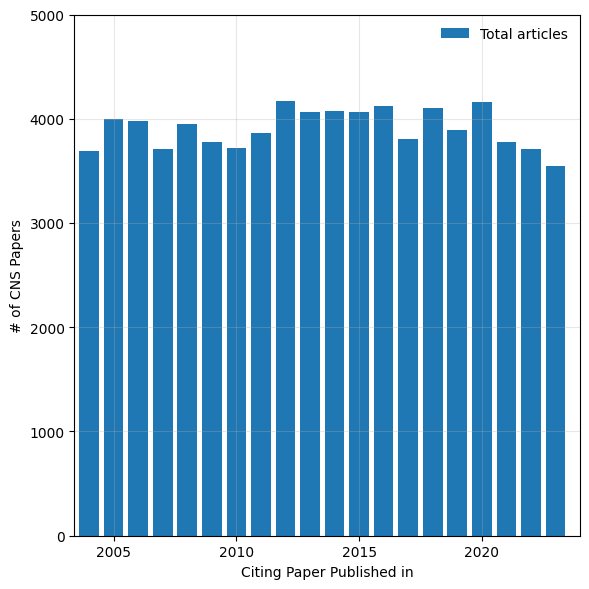

In [12]:

plt.figure(figsize=(6, 6))
plt.bar(CNS_paper_yearly_count["publication_year"].to_list(), CNS_paper_yearly_count["total_article"].to_list(), color="tab:blue", label="Total articles")
plt.xlabel("Citing Paper Published in")
plt.xticks(range(2000, 2030, 5))
plt.xlim(2004 - 0.6, 2024)
plt.ylim(0,5000)
plt.ylabel("# of CNS Papers")
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


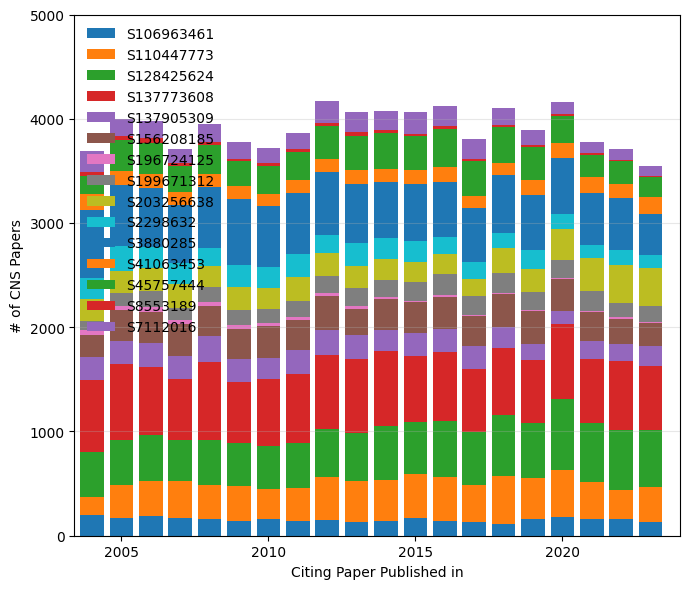

In [13]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

# 1. publication_year × source ごとに件数集計
CNS_paper_yearly_source_count = (
    CNS_papers_details_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by(["publication_year", "primary_location_id"])
    .agg(
        pl.len().alias("total_article"),
        pl.col("ref_count").sum().alias("total_ref_count"),
    )
    .filter(pl.col("publication_year") >= 2000)
    .sort(["publication_year", "primary_location_id"])
)

# 2. 積み上げしやすいように wide 化
plot_df = (
    CNS_paper_yearly_source_count
    .select(["publication_year", "primary_location_id", "total_article"])
    .pivot(
        values="total_article",
        index="publication_year",
        on="primary_location_id",
        aggregate_function="sum",
    )
    .sort("publication_year")
    .fill_null(0)
)

# 3. matplotlib 用に取り出し
years = plot_df["publication_year"].to_list()
source_cols = [c for c in plot_df.columns if c != "publication_year"]

bottom = np.zeros(len(years))

plt.figure(figsize=(7, 6))

for src in source_cols:
    values = plot_df[src].to_numpy()
    plt.bar(years, values, bottom=bottom, label=src)
    bottom += values

plt.xlabel("Citing Paper Published in")
plt.ylabel("# of CNS Papers")
plt.xticks(range(2000, 2030, 5))
plt.xlim(2004 - 0.6, 2024)
plt.ylim(0, 5000)
plt.grid(alpha=0.3, axis="y")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

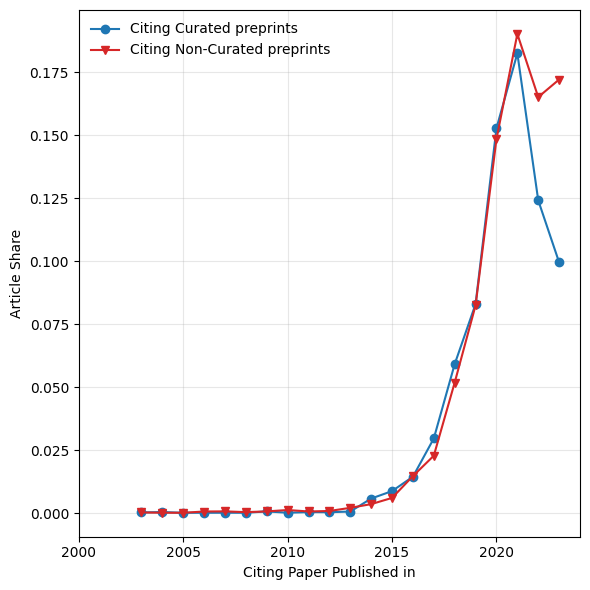

In [75]:
pdf = citing_preprint_probability

plt.figure(figsize=(6, 6))
plt.plot(pdf["publication_year"].to_list(), pdf["citing_curated_preprint_probability"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Citing Curated preprints")
plt.plot(pdf["publication_year"].to_list(), pdf["citing_noncurated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:red", label="Citing Non-Curated preprints")
plt.xlabel("Citing Paper Published in")
plt.xticks(range(2000, 2025, 5))
plt.ylabel("Article Share")
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()

ylims = plt.ylim()
plt.show()


In [76]:
# citation count probability plot

# Sort by publication year to guarantee correct line order
# pdf = citing_preprint_probability

# import matplotlib.pyplot as plt

# plt.figure(figsize=(6, 6))
# plt.plot(pdf["publication_year"].to_list(), pdf["citation_curated_preprint_probability"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Citing Curated preprints")
# plt.plot(pdf["publication_year"].to_list(), pdf["citation_noncurated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:red", label="Citing Non-Curated preprints")
# plt.xticks(range(2000, 2025, 5))

# plt.xlabel("Citing Paper Published in")
# plt.ylabel("Probability of Citing Preprints")
# # plt.title("Probability of Citing Preprints by Publication Year (CNS journals, inception Before 2000)")
# plt.grid(alpha=0.3)
# plt.legend(frameon=False)
# plt.tight_layout()

# # ylims = plt.ylim()
# # If running in a notebook, show the figure
# plt.show()


In [145]:
bins = [2010, 2015, 2020, 2025]
citing_year_gap = (
    CNS_citing_preprints_df
    .with_columns(
        (pl.col("publication_year") - pl.col("publication_year_preprint")).alias("year_gap"),
        pl.col("publication_year").cut(breaks=bins).alias("publication_year_bins"),
        pl.col("curated_doi").is_not_null().alias("is_curated"),
    )
    .filter(
        pl.col("year_gap").is_between(0, 30)
    )
    .group_by("publication_year_bins", "is_curated")
    .agg(pl.col("year_gap"))
    .filter(~pl.col("publication_year_bins").cast(pl.Utf8).str.contains("-inf"))
    .sort("publication_year_bins")
)

/tmp/ipykernel_9083/3325284852.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Greens')


3
184
7754
16224


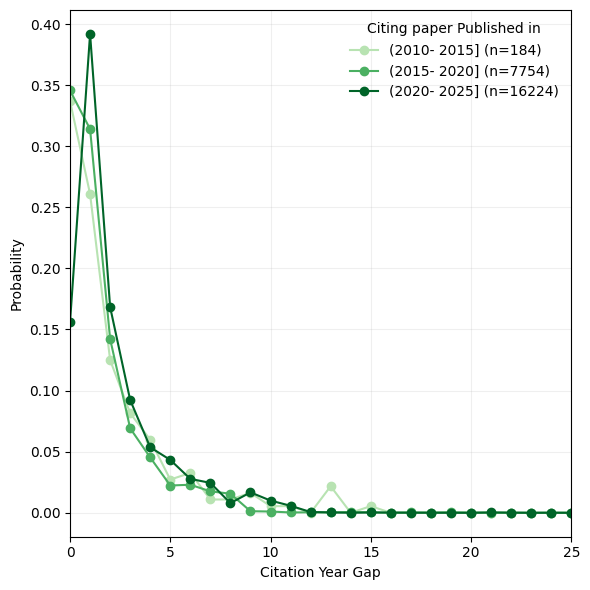

In [146]:
# PMF of year gaps by publication_year_bins (Polars-only, overlaid lines with green gradient)
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm

# Use the grouped 'citing_year_gap' (list column) and explode to rows
df = citing_year_gap
exploded = df.explode('year_gap')

# ensure integer year gaps and readable bin labels
exploded = exploded.with_columns(pl.col('year_gap').cast(pl.Int64), pl.col('publication_year_bins').cast(pl.Utf8))
bins_ = exploded['publication_year_bins'].unique().sort().to_list()
# if "(" in bins_[0]:  # check if the bin labels are in the form of "(2010, 2015]"
labels = [f"{bins_[i].split(',')[0]}-{bins_[i].split(',')[1]}" for i in range(len(bins_))]

xbins = np.arange(0, 31, 1)
cmap = cm.get_cmap('Greens')
n = len(bins_)
# sample the Greens colormap from light to deep
colors = [cmap(0.3 + 0.6 * i / max(1, n - 1)) for i in range(n)]
print(len(colors))
plt.figure(figsize=(6, 6))
for i, b in enumerate(bins_):
    grp = exploded.filter(pl.col('publication_year_bins') == b)
    print(len(grp))
    # compute integer counts per year_gap using Polars
    counts_df = grp.group_by('year_gap').agg(pl.count('year_gap').alias('count')).sort('year_gap')
    if counts_df.height == 0:
        continue
    counts_map = {int(k): int(v) for k, v in zip(counts_df['year_gap'].to_list(), counts_df['count'].to_list())}
    counts_arr = np.array([counts_map.get(x, 0) for x in xbins], dtype=float)
    total = counts_arr.sum()
    if total == 0:
        continue
    pmf = counts_arr / total
    # plot PMF as a line with markers
    plt.plot(xbins, pmf, marker='o', linestyle='-', color=colors[i], label=f"{labels[i]} (n={int(total)})")
plt.xlabel('Citation Year Gap')
plt.ylabel('Probability')
# plt.title('PMF of year gaps by publication year bins')
plt.xlim(0, 25)
plt.grid(alpha=0.2)
plt.legend(title='Citing paper Published in', loc='upper right',frameon=False)
plt.tight_layout()
plt.show()

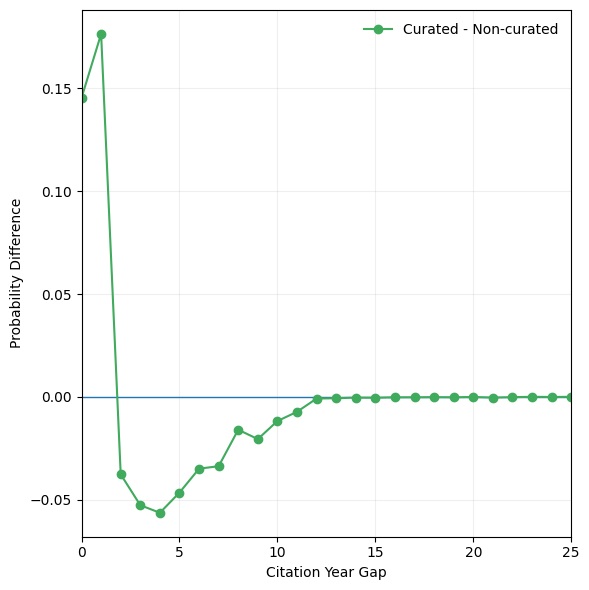

In [153]:


# publication_year_bins を潰して、全期間で curated / non-curated ごとの gap 分布にする
exploded = (
    citing_year_gap
    .explode("year_gap")
    .with_columns(pl.col("year_gap").cast(pl.Int64))
    .select(["is_curated", "year_gap"])
)

# gap ごとの件数
counts = (
    exploded
    .group_by(["is_curated", "year_gap"])
    .agg(pl.len().alias("count"))
    .sort(["is_curated", "year_gap"])
)

# 各群の総数
totals = (
    counts
    .group_by("is_curated")
    .agg(pl.col("count").sum().alias("total"))
)

# 確率に変換
pmf = (
    counts
    .join(totals, on="is_curated", how="left")
    .with_columns((pl.col("count") / pl.col("total")).alias("prob"))
    .select(["is_curated", "year_gap", "prob"])
)

# curated / non-curated を横持ち
pmf_wide = (
    pmf
    .pivot(
        values="prob",
        index="year_gap",
        on="is_curated",
        aggregate_function="first",
    )
    .rename({
        "true": "curated",
        "false": "non_curated",
    })
    .sort("year_gap")
    .with_columns(
        pl.col("curated").fill_null(0.0),
        pl.col("non_curated").fill_null(0.0),
    )
    .with_columns(
        (pl.col("curated") - pl.col("non_curated")).alias("diff")
    )
)

# 0..30 を全部並べたい場合
all_gaps = pl.DataFrame({"year_gap": np.arange(0, 31, 1)})
pmf_wide = (
    all_gaps
    .join(pmf_wide, on="year_gap", how="left")
    .with_columns(
        pl.col("curated").fill_null(0.0),
        pl.col("non_curated").fill_null(0.0),
        pl.col("diff").fill_null(0.0),
    )
)

# plot
x = pmf_wide["year_gap"].to_numpy()
y = pmf_wide["diff"].to_numpy()

plt.figure(figsize=(6, 6))
plt.axhline(0, linewidth=1)
plt.plot(x, y, marker="o", linestyle="-", label="Curated - Non-curated", color=colors[1])
plt.xlabel("Citation Year Gap")
plt.ylabel("Probability Difference")
plt.xlim(0, 25)
plt.grid(alpha=0.2)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

/tmp/ipykernel_9083/477585717.py:48: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(
/tmp/ipykernel_9083/477585717.py:98: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("Greens")


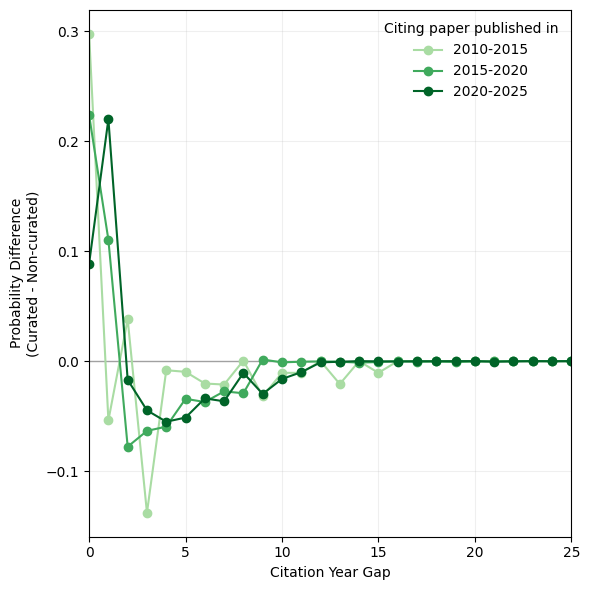

In [147]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm

# citing_year_gap:
#   publication_year_bins
#   is_curated
#   year_gap (list)
# を持っている前提

# 1. explode して1行1gapにする
exploded = (
    citing_year_gap
    .explode("year_gap")
    .with_columns(
        pl.col("year_gap").cast(pl.Int64),
        pl.col("publication_year_bins").cast(pl.Utf8),
    )
    .select(["publication_year_bins", "is_curated", "year_gap"])
)

# 2. 各 period × curated/non-curated × gap の count
counts = (
    exploded
    .group_by(["publication_year_bins", "is_curated", "year_gap"])
    .agg(pl.len().alias("count"))
)

# 3. 各 period × curated/non-curated の total
totals = (
    counts
    .group_by(["publication_year_bins", "is_curated"])
    .agg(pl.col("count").sum().alias("total"))
)

# 4. 確率化
pmf = (
    counts
    .join(totals, on=["publication_year_bins", "is_curated"], how="left")
    .with_columns((pl.col("count") / pl.col("total")).alias("prob"))
    .select(["publication_year_bins", "is_curated", "year_gap", "prob"])
)

# 5. period × gap ごとに curated / non_curated を横持ち
pmf_wide = (
    pmf
    .pivot(
        values="prob",
        index=["publication_year_bins", "year_gap"],
        columns="is_curated",
        aggregate_function="first",
    )
    .rename({
        "true": "curated",
        "false": "non_curated",
    })
    .with_columns(
        pl.col("curated").fill_null(0.0),
        pl.col("non_curated").fill_null(0.0),
    )
    .with_columns(
        (pl.col("curated") - pl.col("non_curated")).alias("diff")
    )
    .sort(["publication_year_bins", "year_gap"])
)

# 6. gap=0..30 を各 period で埋める
periods = pmf_wide["publication_year_bins"].unique().sort().to_list()
all_gaps = np.arange(0, 31, 1)

grid = pl.DataFrame({
    "publication_year_bins": np.repeat(periods, len(all_gaps)),
    "year_gap": np.tile(all_gaps, len(periods)),
})

pmf_wide = (
    grid
    .join(pmf_wide, on=["publication_year_bins", "year_gap"], how="left")
    .with_columns(
        pl.col("curated").fill_null(0.0),
        pl.col("non_curated").fill_null(0.0),
        pl.col("diff").fill_null(0.0),
    )
    .sort(["publication_year_bins", "year_gap"])
)

# 7. ラベル整形
def format_bin_label(s):
    # 例: "[2010, 2015)" や "(2010,2015]" をざっくり読みやすく
    s = s.replace("[", "").replace("]", "").replace("(", "").replace(")", "")
    left, right = [x.strip() for x in s.split(",")]
    return f"{left}-{right}"

labels = {p: format_bin_label(p) for p in periods}

# 8. plot
cmap = cm.get_cmap("Greens")
n = len(periods)
colors = [cmap(0.35 + 0.55 * i / max(1, n - 1)) for i in range(n)]

plt.figure(figsize=(6, 6))
plt.axhline(0, linewidth=1, color="gray", alpha=0.7)

for i, p in enumerate(periods):
    grp = pmf_wide.filter(pl.col("publication_year_bins") == p).sort("year_gap")
    x = grp["year_gap"].to_numpy()
    y = grp["diff"].to_numpy()
    plt.plot(
        x, y,
        marker="o",
        linestyle="-",
        color=colors[i],
        label=labels[p],
    )

plt.xlabel("Citation Year Gap")
plt.ylabel("Probability Difference\n(Curated - Non-curated)")
plt.xlim(0, 25)
plt.grid(alpha=0.2)
plt.legend(title="Citing paper published in", frameon=False)
plt.tight_layout()
plt.show()

In [160]:
# 95 % confidence interval of mean
def ci_mean(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    mean = np.mean(a)
    se = np.std(a, ddof=1) / np.sqrt(n)
    h = se * 1.96  # for 95% confidence
    return mean, mean - h, mean + h

ci_means = [ci_mean(citing_year_gap.filter(pl.col("publication_year_bins") == b)["year_gap"].to_numpy()[0]) for b in bins_]


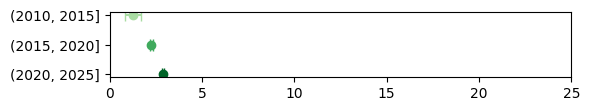

In [161]:
import numpy as np
import matplotlib.pyplot as plt

# 例: ci_means = [(mean, lower, upper), ...]
# bins_ は対応するラベル (e.g. ["2010–2012", "2013–2015", ...])

# 平均値・下限・上限をそれぞれ抽出
means = [m for m, l, u in ci_means]
lower = [m - l for m, l, u in ci_means]  # 左側誤差
upper = [u - m for m, l, u in ci_means]  # 右側誤差
errors = [lower, upper]

# 図の作成
fig, ax = plt.subplots(figsize=(6, 0.4 * len(bins_)))

y_pos = np.arange(len(bins_))

# 横方向のエラーバー（T字型）
for i in range(len(bins_)):    
    ax.errorbar(
        means[i], y_pos[i], xerr=[[lower[i]], [upper[i]]],
        fmt='o', color=colors[i], ecolor=colors[i], elinewidth=1.5, capsize=4
    )

# 軸設定
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.invert_yaxis()  # 上から古い年順などにする場合
# ax.set_xlabel("Mean citing year gap (±95% CI)")
# ax.set_title("95% confidence intervals of mean by publication year bin")
ax.set_xlim(0, 25)

plt.tight_layout()
plt.show()

In [157]:
import polars as pl

summary_stats = (
    citing_year_gap
    .explode("year_gap")
    .with_columns(
        pl.col("year_gap").cast(pl.Float64),
        pl.col("publication_year_bins").cast(pl.Utf8),
    )
    .group_by(["publication_year_bins", "is_curated"])
    .agg(
        pl.len().alias("n"),
        pl.col("year_gap").mean().alias("mean_year_gap"),
        pl.col("year_gap").var(ddof=1).alias("var_year_gap"),
        pl.col("year_gap").std(ddof=1).alias("std_year_gap"),
    )
    .sort(["publication_year_bins", "is_curated"])
)

summary_stats

summary_wide = (
    summary_stats
    .pivot(
        values=["n", "mean_year_gap", "var_year_gap", "std_year_gap"],
        index="publication_year_bins",
        columns="is_curated",
        aggregate_function="first",
    )
    .rename({
        "n_true": "n_curated",
        "n_false": "n_noncurated",
        "mean_year_gap_true": "mean_curated",
        "mean_year_gap_false": "mean_noncurated",
        "var_year_gap_true": "var_curated",
        "var_year_gap_false": "var_noncurated",
        "std_year_gap_true": "std_curated",
        "std_year_gap_false": "std_noncurated",
    })
    .sort("publication_year_bins")
)

summary_wide

/tmp/ipykernel_9083/2358325500.py:24: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(


publication_year_bins,n_noncurated,n_curated,mean_noncurated,mean_curated,var_noncurated,var_curated,std_noncurated,std_curated
str,u32,u32,f64,f64,f64,f64,f64,f64
"""(2010, 2015]""",94,90,2.93617,1.255556,11.350721,4.214856,3.369083,2.053012
"""(2015, 2020]""",3750,4004,2.2624,0.884366,5.666524,1.489248,2.380446,1.220348
"""(2020, 2025]""",9027,7197,2.877257,1.312352,7.349213,1.575018,2.710943,1.254997


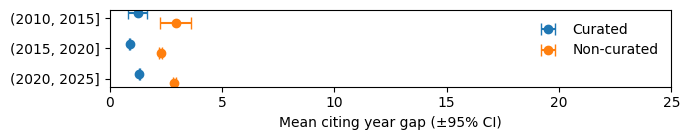

In [158]:
import numpy as np
import matplotlib.pyplot as plt

plot_df = (
    citing_year_gap
    .explode("year_gap")
    .with_columns(
        pl.col("year_gap").cast(pl.Float64),
        pl.col("publication_year_bins").cast(pl.Utf8),
    )
    .group_by(["publication_year_bins", "is_curated"])
    .agg(
        pl.len().alias("n"),
        pl.col("year_gap").mean().alias("mean"),
        pl.col("year_gap").std(ddof=1).alias("std"),
    )
    .with_columns(
        (pl.col("std") / pl.col("n").sqrt() * 1.96).alias("ci_half")
    )
    .sort(["publication_year_bins", "is_curated"])
)

bins_ = plot_df["publication_year_bins"].unique().sort().to_list()
y = np.arange(len(bins_))

cur = plot_df.filter(pl.col("is_curated") == True).sort("publication_year_bins")
non = plot_df.filter(pl.col("is_curated") == False).sort("publication_year_bins")

fig, ax = plt.subplots(figsize=(7, 0.5 * len(bins_)))

offset = 0.15

ax.errorbar(
    cur["mean"].to_numpy(), y - offset,
    xerr=cur["ci_half"].to_numpy(),
    fmt="o", capsize=4, label="Curated"
)

ax.errorbar(
    non["mean"].to_numpy(), y + offset,
    xerr=non["ci_half"].to_numpy(),
    fmt="o", capsize=4, label="Non-curated"
)

ax.set_yticks(y)
ax.set_yticklabels(bins_)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xlabel("Mean citing year gap (±95% CI)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [150]:
for v in zip(means, lower, upper):
    print(f"Mean: {v[0]:.2f}, 95% CI: ({v[0] - v[1]:.2f}, {v[0] + v[2]:.2f})")

Mean: 1.26, 95% CI: (0.83, 1.68)
Mean: 2.26, 95% CI: (2.19, 2.34)
Mean: 2.88, 95% CI: (2.82, 2.93)


# removing specific preprints
- top cited preprints
- COVID-19 related preprints (or journal papers)

In [17]:
# CNS_preprints_cited_by_count = (
#     CNS_citing_preprints_df
#     .join(journal_detail, on="primary_location_id", how="inner")
#     .group_by("referenced_works").agg(
#         pl.count("work_id").alias("cited_by_count"),
#         pl.col("primary_category").first().alias("primary_category"),
#         pl.col("server").first().alias("server"),
#         pl.col("curated_doi").first().alias("curated_doi"),
#     )
# )
# CNS_preprints_cited_by_count

In [18]:
quantile = 0.9
filter_articles_id = (
    CNS_citing_preprints_df
    .group_by("referenced_works")
    .len()
    .filter(
        pl.col("len") < pl.col("len").quantile(quantile)
    )
    .select("referenced_works")
)

In [19]:
import polars as pl

quantiles = [0.99, 0.95, 0.9]

def compute_probabilities_for_quantile(q):
    filter_articles_id = (
        CNS_citing_preprints_df
        .group_by("referenced_works")
        .len()
        .filter(pl.col("len") < pl.col("len").quantile(q))
        .select("referenced_works")
    )

    pub_year_counts = (
        CNS_citing_preprints_df
        .join(journal_detail, on="primary_location_id", how="inner")
        .join(filter_articles_id, on="referenced_works", how="semi")
        .filter(pl.col("inception_period") == "Before 2000")
        .unique("work_id")
        .group_by("publication_year")
        .agg(
            pl.col("curated_doi").is_not_null().sum()
              .alias(f"num_citing_curated_preprints_q{q}"),
            pl.col("curated_doi").is_null().sum()
              .alias(f"num_citing_noncurated_preprints_q{q}")
        )
    )

    return (
        pub_year_counts
        .join(CNS_paper_yearly_count, on="publication_year", how="inner")
        .filter(pl.col("publication_year").is_between(2000, 2024))
        .with_columns(
            (pl.col(f"num_citing_curated_preprints_q{q}") / pl.col("total_article"))
              .alias(f"citing_curated_preprint_probability_q{q}"),
            (pl.col(f"num_citing_noncurated_preprints_q{q}") / pl.col("total_article"))
              .alias(f"citing_noncurated_preprint_probability_q{q}")
        )
        .select(
            "publication_year",
            f"citing_curated_preprint_probability_q{q}",
            f"citing_noncurated_preprint_probability_q{q}",
        )
        .sort("publication_year")
    )

# quantile ごとの結果を作成
dfs = [compute_probabilities_for_quantile(q) for q in quantiles]

# publication_year で横結合
result_df = dfs[0]
for df in dfs[1:]:
    result_df = result_df.join(df, on="publication_year", how="inner")

result_df

publication_year,citing_curated_preprint_probability_q0.99,citing_noncurated_preprint_probability_q0.99,citing_curated_preprint_probability_q0.95,citing_noncurated_preprint_probability_q0.95,citing_curated_preprint_probability_q0.9,citing_noncurated_preprint_probability_q0.9
i64,f64,f64,f64,f64,f64,f64
2003,0.0,0.00038,0.0,0.00038,0.0,0.00038
2004,0.000542,0.0,0.000542,0.0,0.000542,0.0
2005,0.0,0.00025,0.0,0.00025,0.0,0.00025
2006,0.0,0.000753,0.0,0.000753,0.0,0.000753
2007,0.0,0.00081,0.0,0.00081,0.0,0.00081
…,…,…,…,…,…,…
2019,0.06401,0.045501,0.058612,0.035476,0.052956,0.032134
2020,0.115994,0.082133,0.100144,0.071806,0.091018,0.065082
2021,0.128443,0.114672,0.119439,0.096398,0.10964,0.086335


In [20]:
CNS_citing_preprints_df.head()

work_id,referenced_works,doi,primary_category,server,curated_doi,published_date,publication_year_preprint,primary_location_id,publication_year
str,str,str,str,str,str,datetime[μs],i32,str,i64
"""W4389729874""","""W4310253617""","""10.1101/2022.11.22.22282629""","""epidemiology""","""medrxiv""",null,2022-11-27 00:00:00,2022,"""S110447773""",2023
"""W3215743644""","""W2101234009""","""10.48550/arxiv.1201.0490""","""cs.LG""","""arxiv""",null,2012-01-02 00:00:00,2012,"""S169236886""",2021
"""W3215743644""","""W4300122070""","""10.48550/arxiv.1803.11136""","""stat.ML""","""arxiv""",null,2018-03-29 00:00:00,2018,"""S169236886""",2021
"""W3215743644""","""W2580527863""","""10.48550/arxiv.1701.06772""","""cs.CV""","""arxiv""",null,2017-01-24 00:00:00,2017,"""S169236886""",2021
"""W3215743644""","""W2775795276""","""10.48550/arxiv.1712.04621""","""cs.CV""","""arxiv""",null,2017-12-13 00:00:00,2017,"""S169236886""",2021


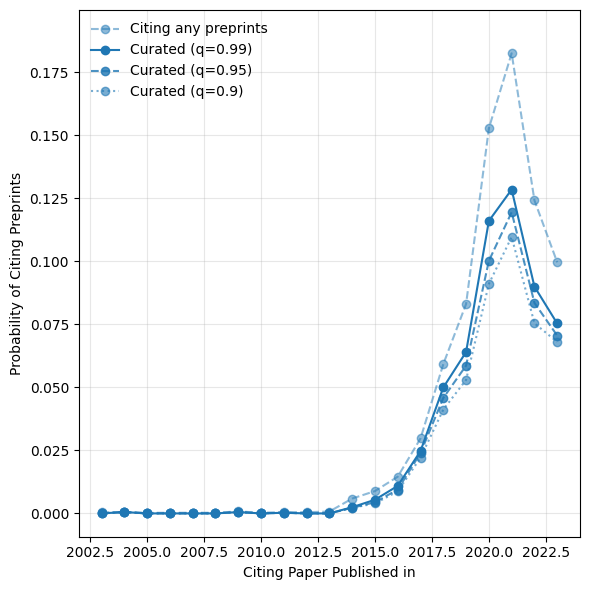

In [21]:
# 6列版 DataFrame
pdf_cut = result_df.sort("publication_year")

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

quantiles = [0.99, 0.95, 0.9]
linestyles = ["-", "--", ":"]
alphas = [1.0, 0.8, 0.6]

plt.plot(pdf["publication_year"].to_list(), pdf["citing_curated_preprint_probability"].to_list(), marker="o", linestyle="--", alpha=0.5, color="tab:blue", label="Citing any preprints")

for q, ls, a in zip(quantiles, linestyles, alphas):
    plt.plot(
        pdf_cut["publication_year"].to_list(),
        pdf_cut[f"citing_curated_preprint_probability_q{q}"].to_list(),
        marker="o",
        linestyle=ls,
        alpha=a,
        color="tab:blue",
        label=f"Curated (q={q})"
    )

plt.xlabel("Citing Paper Published in")
plt.ylabel("Probability of Citing Preprints")
plt.grid(alpha=0.3)
plt.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.ylim(ylims)

plt.show()

In [22]:
# quantile = 0.9
# filter_articles_id = CNS_citing_preprints_df.group_by("referenced_works").len().filter(pl.col("len") < pl.col("len").quantile(quantile)).select("referenced_works")

# pub_year_preprint_citation_count_filtered =(
#     CNS_citing_preprints_df
#     .join(journal_detail, on="primary_location_id", how="inner")
#     .join(filter_articles_id, on="referenced_works", how="semi")
#     .filter(pl.col("inception_period") == "Before 2000")
#     .unique("work_id")
#     .group_by("publication_year")
#     .agg(
#         # pl.count("work_id").alias("num_citing_preprints"),
#         pl.col("curated_doi").is_not_null().sum().alias("num_citing_curated_preprints"),
#         pl.col("curated_doi").is_null().sum().alias("num_citing_noncurated_preprints")
#     )
#     .sort("publication_year")
# )

# citing_preprint_probability_filtered = (
#     pub_year_preprint_citation_count_filtered
#     .join(CNS_paper_yearly_count, on="publication_year", how="inner")
#     .filter(pl.col("publication_year").is_between(2000,2024))
#     .with_columns(
#         (pl.col("num_citing_curated_preprints") / pl.col("total_article")).alias("citing_curated_preprint_probability"),
#         (pl.col("num_citing_noncurated_preprints") / pl.col("total_article")).alias("citing_noncurated_preprint_probability")
#     )
#     .sort("publication_year")
# )

# # Sort by publication year to guarantee correct line order
# pdf_cut = citing_preprint_probability_filtered

# import matplotlib.pyplot as plt

# plt.figure(figsize=(6, 6))
# # plt.plot(pdf["publication_year"].to_list(), pdf["citing_preprint_probability"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Citing any preprints")
# plt.plot(pdf["publication_year"].to_list(), pdf["citing_curated_preprint_probability"].to_list(), marker="o", linestyle="--", alpha=0.5, color="tab:blue", label="Citing any preprints")
# plt.plot(pdf["publication_year"].to_list(), pdf["citing_noncurated_preprint_probability"].to_list(), marker="v", linestyle="--", alpha=0.5,color="tab:red", label="Citing Non-Curated preprints")
# plt.plot(pdf_cut["publication_year"].to_list(), pdf_cut["citing_curated_preprint_probability"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Citing any preprints")
# plt.plot(pdf_cut["publication_year"].to_list(), pdf_cut["citing_noncurated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:red", label="Citing Non-Curated preprints")
# plt.xlabel("Citing Paper Published in")
# plt.ylabel("Probability of Citing Preprints")
# # plt.title("Probability of Citing Preprints by Publication Year (CNS journals, inception Before 2000)")
# plt.grid(alpha=0.3)
# # plt.legend(frameon=False, loc="upper left")
# plt.tight_layout()
# plt.ylim(ylims)

In [23]:
import math
import polars as pl

# 前処理：curated フラグを明示
base = (
    CNS_citing_preprints_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .filter(pl.col("publication_year").is_between(2013, 2024))
    .with_columns(
        pl.col("curated_doi").is_not_null().alias("is_curated")
    )
    .select([
        "publication_year",
        "referenced_works",
        "is_curated",
    ])
)

qs = [1, 5, 10]
B = 1000  # bootstrap 回数

def bootstrap_top_share(df_year, q, B=1000):
    """
    df_year: 1年分・curated の citation events
    q: top q%
    """
    shares = []

    M = df_year.height
    if M == 0:
        return np.nan, np.nan, np.nan

    for _ in range(B):
        sampled = df_year.sample(n=M, with_replacement=True)

        counts = (
            sampled
            .group_by("referenced_works")
            .len()
            .sort("len", descending=True)
        )

        n = counts.height
        k = max(1, math.ceil(n * q / 100))

        share = counts.head(k)["len"].sum() / counts["len"].sum()
        shares.append(share)

    lo, mid, hi = np.percentile(shares, [2.5, 50, 97.5])
    return mid, lo, hi

def top_share_for_year_and_type(df, q):
    """
    df: ある1年 × (curated or non-curated) の DataFrame
    q: top q%
    """
    counts = (
        df
        .group_by("referenced_works")
        .len()
        .rename({"len": "cites"})
        .sort("cites", descending=True)
    )

    n = counts.height
    if n == 0:
        return float("nan")

    k = max(1, math.ceil(n * (q / 100.0)))
    top_cites = counts.head(k)["cites"].sum()
    total_cites = counts["cites"].sum()

    return float(top_cites / total_cites)
rows = []

years = (
    base
    .filter(pl.col("is_curated") == True)
    .select("publication_year")
    .unique()
    .sort("publication_year")
    .get_column("publication_year")
    .to_list()
)

for y in years:
    df_y = base.filter(
        (pl.col("publication_year") == y) &
        (pl.col("is_curated") == True)
    )

    for q in qs:
        mid, lo, hi = bootstrap_top_share(df_y, q, B=B)

        rows.append({
            "publication_year": y,
            "q": q,
            "top_share": mid,
            "ci_low": lo,
            "ci_high": hi,
        })

top_share_boot_df = pl.DataFrame(rows).sort(["q", "publication_year"])
# top_share_boot_df
# years = (
#     base.select("publication_year")
#     .unique()
#     .sort("publication_year")
#     .get_column("publication_year")
#     .to_list()
# )

# rows = []
# for y in years:
#     for is_curated in [True, False]:
#         df_sub = base.filter(
#             (pl.col("publication_year") == y) &
#             (pl.col("is_curated") == is_curated)
#         )

#         row = {
#             "publication_year": y,
#             "type": "curated" if is_curated else "noncurated",
#         }

#         for q in qs:
#             row[f"top{q}_share"] = top_share_for_year_and_type(df_sub, q)

#         rows.append(row)

# top_share_df = (
#     pl.DataFrame(rows)
#     .sort(["type", "publication_year"])
# )

# top_share_df

In [24]:
years

[2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

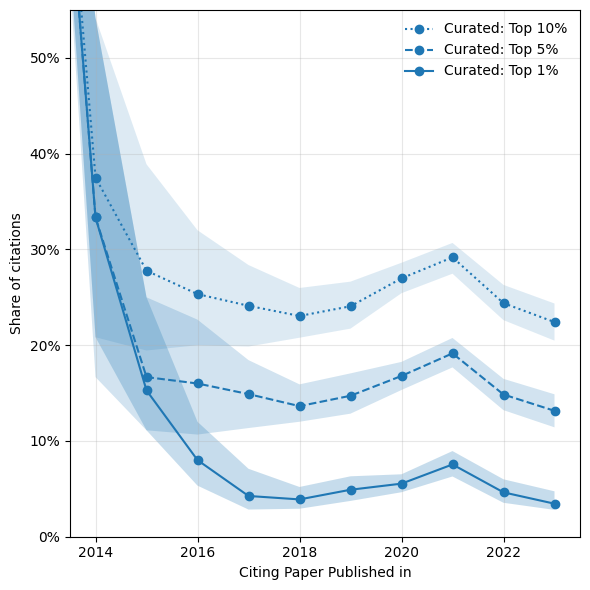

In [25]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6, 6))

linestyles = {1: "-", 5: "--", 10: ":"}
alphas = {1: 0.25, 5: 0.20, 10: 0.15}

for q in [1, 5, 10]:
    pdf_ = (
        top_share_boot_df
        .filter(pl.col("q") == q)
        .sort("publication_year")
    )

    years = pdf_["publication_year"].to_list()
    mid   = pdf_["top_share"].to_list()
    lo    = pdf_["ci_low"].to_list()
    hi    = pdf_["ci_high"].to_list()

    # 中央値
    plt.plot(
        years,
        mid,
        marker="o",
        color="tab:blue",
        linestyle=linestyles[q],
        label=f"Curated: Top {q}%"
    )

    # 95% CI
    plt.fill_between(
        years,
        lo,
        hi,
        color="tab:blue",
        alpha=alphas[q],
        linewidth=0
    )

plt.xlabel("Citing Paper Published in")
plt.ylabel("Share of citations")
plt.yticks(
    np.linspace(0, 0.5, 6),
    [f"{v:.0%}" for v in np.linspace(0, 0.5, 6)]
)
plt.ylim(0, 0.55)
plt.xlim(2013.5, 2023.5)
plt.grid(alpha=0.3)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles[::-1],
    labels[::-1],
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

In [26]:
mid

[1.0,
 0.375,
 0.2777777777777778,
 0.25333333333333335,
 0.24113475177304963,
 0.2305194805194805,
 0.24065420560747663,
 0.2697636511817441,
 0.2917540181691125,
 0.2438692098092643,
 0.22413793103448276]

In [27]:
rows = []

for y in years:
    df_y = base.filter(
        (pl.col("publication_year") == y) &
        (pl.col("is_curated") == False)
    )

    for q in qs:
        mid, lo, hi = bootstrap_top_share(df_y, q, B=B)

        rows.append({
            "publication_year": y,
            "q": q,
            "top_share": mid,
            "ci_low": lo,
            "ci_high": hi,
        })

top_share_boot_non_curated_df = pl.DataFrame(rows).sort(["q", "publication_year"])

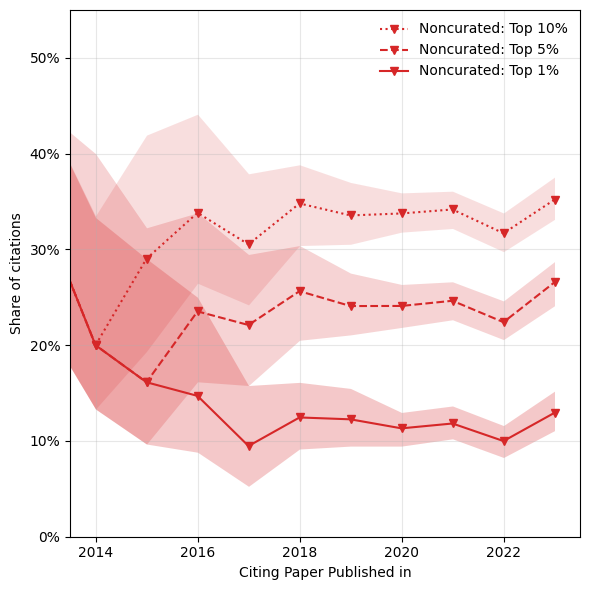

In [28]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(6, 6))

linestyles = {1: "-", 5: "--", 10: ":"}
alphas = {1: 0.25, 5: 0.20, 10: 0.15}

for q in [1, 5, 10]:
    pdf_ = (
        top_share_boot_non_curated_df
        .filter(pl.col("q") == q)
        .sort("publication_year")
    )

    years = pdf_["publication_year"].to_list()
    mid   = pdf_["top_share"].to_list()
    lo    = pdf_["ci_low"].to_list()
    hi    = pdf_["ci_high"].to_list()

    # 中央値
    plt.plot(
        years,
        mid,
        marker="v",
        color="tab:red",
        linestyle=linestyles[q],
        label=f"Noncurated: Top {q}%"
    )

    # 95% CI
    plt.fill_between(
        years,
        lo,
        hi,
        color="tab:red",
        alpha=alphas[q],
        linewidth=0
    )

plt.xlabel("Citing Paper Published in")
plt.ylabel("Share of citations")
plt.yticks(
    np.linspace(0, 0.5, 6),
    [f"{v:.0%}" for v in np.linspace(0, 0.5, 6)]
)
plt.ylim(0, 0.55)
plt.grid(alpha=0.3)
plt.xlim(2013.5, 2023.5)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(
    handles[::-1],
    labels[::-1],
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

In [ ]:
import math
import polars as pl

# 前処理：curated フラグを明示
base = (
    CNS_citing_preprints_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .filter(pl.col("publication_year").is_between(2013, 2024))
    .with_columns(
        pl.col("curated_doi").is_not_null().alias("is_curated")
    )
    .select([
        "publication_year",
        "referenced_works",
        "is_curated",
    ])
)

qs = [1, 5, 10]
B = 1000  # bootstrap 回数

def bootstrap_top_share(df_year, q, B=1000):
    """
    df_year: 1年分・curated の citation events
    q: top q%
    """
    shares = []

    M = df_year.height
    if M == 0:
        return np.nan, np.nan, np.nan

    for _ in range(B):
        sampled = df_year.sample(n=M, with_replacement=True)

        counts = (
            sampled
            .group_by("referenced_works")
            .len()
            .sort("len", descending=True)
        )

        n = counts.height
        k = max(1, math.ceil(n * q / 100))

        share = counts.head(k)["len"].sum() / counts["len"].sum()
        shares.append(share)

    lo, mid, hi = np.percentile(shares, [2.5, 50, 97.5])
    return mid, lo, hi

def top_share_for_year_and_type(df, q):
    """
    df: ある1年 × (curated or non-curated) の DataFrame
    q: top q%
    """
    counts = (
        df
        .group_by("referenced_works")
        .len()
        .rename({"len": "cites"})
        .sort("cites", descending=True)
    )

    n = counts.height
    if n == 0:
        return float("nan")

    k = max(1, math.ceil(n * (q / 100.0)))
    top_cites = counts.head(k)["cites"].sum()
    total_cites = counts["cites"].sum()

    return float(top_cites / total_cites)
rows = []

years = (
    base
    .filter(pl.col("is_curated") == True)
    .select("publication_year")
    .unique()
    .sort("publication_year")
    .get_column("publication_year")
    .to_list()
)

for y in years:
    df_y = base.filter(
        (pl.col("publication_year") == y) &
        (pl.col("is_curated") == True)
    )

    for q in qs:
        mid, lo, hi = bootstrap_top_share(df_y, q, B=B)

        rows.append({
            "publication_year": y,
            "q": q,
            "top_share": mid,
            "ci_low": lo,
            "ci_high": hi,
        })

top_share_boot_df = pl.DataFrame(rows).sort(["q", "publication_year"])

# citation from COVID-19 related papers

In [29]:
from constant import openalex_path

title_lf = pl.scan_parquet(openalex_path + "/works/display_name/*")

CNS_abstract = (
    CNS_papers_details_df
    .lazy().join(title_lf, on="work_id", how="left")
    .collect(engine='streaming')
)
# abstract_lf = pl.scan_parquet(openalex_path + "/works/abstract/*")

# CNS_abstract = (
#     CNS_papers_details_df
#     .lazy().join(abstract_lf, on="work_id", how="left")
#     .collect(engine='streaming')
# )

CNS_abstract.group_by(pl.col("display_name").is_null()).agg(pl.count())

/tmp/ipykernel_97426/2883637969.py:8: UserWarning: '(default_)region' not set; polars will try to get it from bucket

Set the region manually to silence this warning.
  .collect(engine='streaming')
/tmp/ipykernel_97426/2883637969.py:18: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  CNS_abstract.group_by(pl.col("display_name").is_null()).agg(pl.count())


display_name,count
bool,u32
false,228157
true,22


In [30]:
CNS_abstract.group_by(pl.col("display_name").is_null()).agg(pl.count())

/tmp/ipykernel_97426/2368792809.py:1: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  CNS_abstract.group_by(pl.col("display_name").is_null()).agg(pl.count())


display_name,count
bool,u32
false,228157
true,22


In [31]:
keywords = [
    "COVID-19",
    "SARS-CoV-2",
    "Coronavirus disease 19",
    "2019-nCoV"
]
covid_related_papers = (
    CNS_abstract
    .filter(pl.col("display_name").str.contains("|".join(keywords), literal=False))
)

In [32]:
CNS_abstract.height, covid_related_papers.height

(228179, 3492)

In [33]:
covid_related_papers.height / CNS_abstract.height *100

1.5303774668133352

In [34]:
CNS_paper_yearly_count = (
    CNS_papers_details_df
    .join(covid_related_papers.select(["work_id"]), on="work_id", how="anti")
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.count().alias("total_article"),
        pl.col("ref_count").sum().alias("total_ref_count")
    )
)

CNS_paper_yearly_count.filter(pl.col("publication_year") >= 2000).sort("publication_year")

/tmp/ipykernel_97426/290848403.py:8: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("total_article"),


publication_year,total_article,total_ref_count
i64,u32,u32
2000,2503,67729
2001,2569,71251
2002,2600,75931
2003,2632,76473
2004,3692,125044
…,…,…
2019,3890,211019
2020,3779,218442
2021,3385,204546


In [35]:
noncurated = pl.when(pl.col("curated_doi").is_null()).then(pl.col("work_id"))
curated = pl.when(pl.col("curated_doi").is_not_null()).then(pl.col("work_id"))

pub_year_preprint_citation_count = (
    CNS_citing_preprints_df
    .join(covid_related_papers.select(["work_id"]), on="work_id", how="anti")
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.n_unique("work_id").alias("num_citing_preprints"),
        pl.count("work_id").alias("num_citation_preprints"),
        noncurated.n_unique().alias("num_citing_noncurated_preprints"),
        noncurated.count().alias("num_citation_noncurated_preprints"),
        curated.n_unique().alias("num_citing_curated_preprints"),
        curated.count().alias("num_citation_curated_preprints"),
    )
    .sort("publication_year")
)

pub_year_preprint_citation_count

publication_year,num_citing_preprints,num_citation_preprints,num_citing_noncurated_preprints,num_citation_noncurated_preprints,num_citing_curated_preprints,num_citation_curated_preprints
i64,u32,u32,u32,u32,u32,u32
1983,1,1,1,1,1,0
1998,2,6,2,6,1,0
1999,2,3,2,1,3,2
2003,1,1,1,1,1,0
2004,2,2,1,0,2,2
…,…,…,…,…,…,…
2019,519,893,321,465,323,428
2020,762,1403,475,729,462,674
2021,831,1719,550,930,486,789


In [36]:
citing_preprint_probability = (
    pub_year_preprint_citation_count
    .join(CNS_paper_yearly_count, on="publication_year", how="inner")
    .filter(pl.col("publication_year").is_between(2000,2024))
    .with_columns(
        (pl.col("num_citing_preprints") / pl.col("total_article")).alias("citing_preprint_probability"),
        (pl.col("num_citing_noncurated_preprints") / pl.col("total_article")).alias("citing_noncurated_preprint_probability"),
        (pl.col("num_citing_curated_preprints") / pl.col("total_article")).alias("citing_curated_preprint_probability"),
        (pl.col("num_citation_preprints") / pl.col("total_ref_count")).alias("citation_preprint_probability"),
        (pl.col("num_citation_noncurated_preprints") / pl.col("total_ref_count")).alias("citation_noncurated_preprint_probability"),
        (pl.col("num_citation_curated_preprints") / pl.col("total_ref_count")).alias("citation_curated_preprint_probability")
    )
    .sort("publication_year")
)

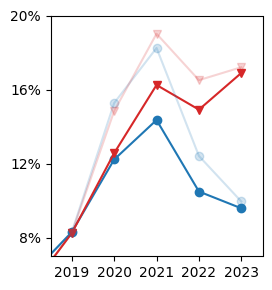

In [38]:
import numpy as np
pdf_2 = citing_preprint_probability #.filter(pl.col("publication_year") >= 2018)

plt.figure(figsize=(3, 3))
plt.plot(pdf_2["publication_year"].to_list(), pdf_2["citing_curated_preprint_probability"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Citing Curated preprints")
plt.plot(pdf_2["publication_year"].to_list(), pdf_2["citing_noncurated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:red", label="Citing Non-Curated preprints")
plt.plot(pdf["publication_year"].to_list(), pdf["citing_curated_preprint_probability"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Citing Curated preprints", alpha=0.2)
plt.plot(pdf["publication_year"].to_list(), pdf["citing_noncurated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:red", label="Citing Non-Curated preprints", alpha=0.2)
plt.xticks(range(2019, 2025))
# y軸はすべて%表示
plt.yticks(
    np.linspace(0.04, 0.2, 5),
    [f"{v:.0%}" for v in np.linspace(0.04   , 0.2, 5)]
)

plt.tight_layout()

plt.xlim(2018.5, 2023.5)
plt.ylim(0.07, 0.20)

ylims = plt.ylim()
plt.show()
